# Homework 5: Deep DOA estimation using a single snapshot

### ELEC-E5481 - Machine Learning for Signal Processing
Write down your name and student number below:<br>
Name: **Nathan Le Magourou** <br>
Student number: **104506992**

AI tools may be used for:
* debugging
* checking syntax
* clarifying concepts
* generating parts of the codes

You must provide an explanation  how you used AI and which functions or parts are AI generated. It is important that you document the codes, understand all parts of it fully (i.e., can explain what it does and why). The code needs to run and provide the results that are presented in the notebook.  This notebook will be your "project report". 

If there is a reason to believe that the AI policy has not been followed, you may be asked to meet with the TA and lecturer to explain your solution. You should be able to discuss your code, reasoning, and approach in detail. Inability to do so will be considered evidence that the work is not your own, and may lead to academic integrity procedures.

In [18]:
import numpy as np
import matplotlib.pyplot as plt

In [15]:
!git clone https://github.com/nathanlemag/doa-estimation-mlp.git
%cd doa-estimation-mlp

Cloning into 'doa-estimation-mlp'...
remote: Enumerating objects: 32, done.
remote: Counting objects: 100% (32/32), done.
remote: Compressing objects: 100% (26/26), done.
remote: Total 32 (delta 6), reused 29 (delta 3), pack-reused 0 (from 0)
Receiving objects: 100% (32/32), 1018.30 KiB | 1.67 MiB/s, done.
Resolving deltas: 100% (6/6), done.
/content/doa-estimation-mlp/doa-estimation-mlp


In [16]:
!rm -rf /content/sample_data

In [17]:
!pip install torchview graphviz

## Project
Implement approach described in the paper PERFORMANCE ADVANTAGES OF DEEP NEURAL NETWORKS FOR ANGLE OF
ARRIVAL ESTIMATION (this was one of the approaches of the group presentations). The paper is also in mycourses.

**You can follow the architecture exactly or make some modifications (with an aim of making the mode work better: having better RMSE performance, having better source detection performance, etc.)** 

Some guidelines: 
* the architecture needs to be **MLP** as in the paper, but you can improvise: in the number of layers used, in number of neurons in the layers, what activation functions you use, what type of tricks you use in the MLP architecture, training, or what loss is used for training, etc.  
* you can keep the same idea of predicting the max 4 sources
* **Do not to put all your code inside the notebook**.  Instead, place most of your implementation in separate `.py` files and simply import the necessary functions or classes into the notebook. The notebook should serve primarily as your **report**: a place where you explain your reasoning, visualize your results, and demonstrate how you are using the code, not where you write the entire project logic. See also comment below. 
* Explain in the report some details of where and how you trained. How many parameters the model has, etc. How difficult it was to train.  
* **Describe the percentage of AI code**  that you used to accomplish the task. For example: **approximate percentage of AI code is 60%**. This is compulsory to report. 
* Save the  final model (`torch.save`), and  attach it in your submission. There is 400MB upload limit in mycourses but I think you should be able to manage without exceeding that size. If your model larger, then just send me an email. 

Grading:
* not super easy to make the approach work....
* we put also emphasis on **learning curve**. You can explain in your report why you could not make it work and what have you learned during the process. 
* _Report can be good even when the results are not stunishing!_ 
* Some ideas of how grading is done is provided form rubric.

**Note:** Aalto offers computer rooms with GPU-machines. You can also think of some other possible resources: Google collab, Kaggle notebook,etc.  However, the model (as described in the paper) is small and can be trained in a laptop. 

_Note_: Below is an example of a good file structure how deep learning codepackages are structured in resarch papers and open-source projects. 

```

project/
├── models/
│   └── network.py
├── data/
│   └── dataloader.py
├── training/
│   ├── trainer.py
│   └── utils.py
├── experiments/
│   └── run_experiment.py
└── report.ipynb
```

The file `data_generation.py` provides an example of data generation which you can adopt/edit to get started. 

## Goal of this notebook
- Use and benchmark ML algorithms (MLP) instead of classic signal processing methods when we only have a single snapshot ($T=1$).
- The number of sources $K$ is unknown.

## Goal of the network
- Estimate the number of sources $K \in \{1, 2, 3, 4\}$.
- Determine their angles of arrival (DOA).

## Data analysis

### `generate_snapshot_dataset` function

#### Inputs
- `nof_snapshots=1` ($T$): number of snapshots (here $T=1$).
- `nof_signals=4` ($K_{\max}$): max number of sources (generates data for $K = 1, 2, 3, 4$).
- `m_elems=16` ($M$): number of antennas in the ULA.
- `SNRs`: list of tested signal-to-noise ratios in dB.
- `fov_start`, `fov_end`: field of view angles, here between $-25^\circ$ and $+25^\circ$ (a $50^\circ$ FOV, like in the paper).
- `samples_per_snr`: number of generated samples for each SNR and each number of sources $K$.

In [19]:
from data.data_generation import generate_snapshot_dataset
import numpy as np

snrs = np.arange(0, 42.5, 2.5)
samples_per_snr = 10000

snapshots, doas = generate_snapshot_dataset(
    nof_snapshots=1,       # Single-snapshot regime (T=1)
    nof_signals=4,         # Up to K=4 sources
    m_elems=16,            # 16-element ULA
    SNRs=snrs,
    fov_start=-25,
    fov_end=25,            # 50° Field of View (matching Fig. 3 in the paper)
    samples_per_snr=samples_per_snr
)

#### How it works
The function runs 3 nested loops:
1. For each SNR (e.g. 17 levels from 0 to 40 dB in steps of 2.5 dB)
2. Loop `samples_per_snr` times (e.g., 10000)
3. For each number of sources $K \in \{1, 2, 3, 4\}$

It returns two dictionaries (`snapshots` and `doas`) indexed by `'1'`, `'2'`, `'3'`, `'4'`:
- `snapshots['K']`: list of `len(SNRs) * samples_per_snr` complex arrays of shape `(M, T)`.
- `doas['K']`: list of `len(SNRs) * samples_per_snr` 1D arrays of shape `(K,)` containing the true angles (ground truth).

### Example

Global size

In [1]:
print("Number of classes (K):", list(snapshots.keys()))
print("Samples per class (17 SNRs * 10000 samples):", len(snapshots['2']))
print("Total dataset size:", sum(len(v) for v in snapshots.values()))

NameError: name 'snapshots' is not defined

In [ ]:
idx = 10000 # First sample of SNR = 2.5 dB (since samples_per_snr = 10000)

Snapshot for for $K=2$, first sample of $\text{SNR} = 2\text{ dB}$.

In [22]:
print("Snapshot shape for K=2:", snapshots['2'][idx].shape)
snapshots['2'][idx]

Snapshot shape for K=2: (16, 1)


array([[-1.51279998+0.38607195j],
       [-0.72294686+0.97740321j],
       [-2.05891821-1.05019306j],
       [ 0.64746308-0.78718093j],
       [ 0.71056696-0.50150647j],
       [ 2.10959292-1.38620682j],
       [ 0.76366743+0.62266463j],
       [ 1.58193167-0.87296265j],
       [ 1.67944314+1.46097428j],
       [ 0.87206012+2.09933969j],
       [-0.54403053+2.23271331j],
       [-0.34446335+2.46048264j],
       [-1.38606289+0.89774708j],
       [-1.40443019-0.06354819j],
       [-0.62873407-1.08669568j],
       [-0.88498525-3.70825867j]])

Ground truth

In [23]:
print("Ground truth DOAs shape for K=2:", doas['2'][idx].shape)
doas['2'][idx]

Ground truth DOAs shape for K=2: (2,)


array([-9.20860392, 13.83059383])

## Handle data

### Imaginary part
Put real and imaginary parts in a single concatenated vector of size $2M$, because a standard MLP doesn't handle complex numbers natively.

### Training data format
- for $K = 1 \rightarrow$ `doa` size is `(1,)`
- for $K = 4 \rightarrow$ `doa` size is `(4,)`

To make fixed-size batches, we store:

Used as input for the MLP:
- `x`: the real vector $[\text{Re}(\mathbf{y}), \text{Im}(\mathbf{y})]$ of size `2*M`

Used for loss / training of the MLP:
- `num_sources`: true number of sources (class index `0` to `3`, scalar)
- `doas`: ground truth sorted and padded with `0` to fixed size `(4,)`

Used for plotting / benchmark:
- `snr`: SNR value of the sample

### Dataset
- Sort true DOAs in ascending order for each sample (so the network always learns a fixed order)
- Gather all data for each $K$ in a single dataset
- Shuffle it
- 80 / 10 / 10 train / validation / test split (standard in ML)

In [24]:
from data.dataloader import prepare_dataloaders

train_loader, val_loader, test_loader = prepare_dataloaders(
    snapshots, doas, snrs=snrs, samples_per_snr=samples_per_snr, batch_size=512
)

x, k, doa, snr = next(iter(train_loader))
print("x:", x.shape, "| true_class:", k.shape, "| true_doas:", doa.shape, "| snr:", snr.shape)

x: torch.Size([512, 32]) | true_class: torch.Size([512]) | true_doas: torch.Size([512, 4]) | snr: torch.Size([512])


### Dataset Batch Structure

Each batch returned by the `DataLoader` (with batch size 512) contains:
- **`x` `(512, 32)`**: L2-normalized real-valued input vectors formed by concatenating the 16 real and 16 imaginary parts of each array snapshot.
- **`true_class` `(512,)`**: Integer class labels in `{0, 1, 2, 3}`, representing $K \in \{1, 2, 3, 4\}$ active sources.
- **`true_doas` `(512, 4)`**: Ground-truth DOA angles sorted in ascending order and zero-padded to length 4 (e.g., `[-12.4, 8.1, 0.0, 0.0]` when $K=2$).
- **`snr` `(512,)`**: The Signal-to-Noise Ratio (in dB) associated with each snapshot.

### Model Architecture
- **Input**: $2N$ neurons (here $16 \times 2 = 32$)
- **Hidden layers**: `[64, 64, 128, 256, 512, 1024, 2048, 256]` with `BatchNorm1d` and `ReLU` after each linear layer
- **Outputs** (5 heads in parallel from the 256-neuron layer, 14 neurons total):
  - `head_class`: `Linear(256, 4)` $\rightarrow$ predicts the number of sources ($K \in \{1, 2, 3, 4\}$)
  - `head_1`: `Linear(256, 1)` $\rightarrow$ predicts 1 angle if $K=1$
  - `head_2`: `Linear(256, 2)` $\rightarrow$ predicts 2 angles if $K=2$
  - `head_3`: `Linear(256, 3)` $\rightarrow$ predicts 3 angles if $K=3$
  - `head_4`: `Linear(256, 4)` $\rightarrow$ predicts 4 angles if $K=4$

### Loss Function

During training, the network processes data in **batches of size $B$** (e.g., $B = (512$ snapshots processed in parallel).  
For a batch, the network produces:
- `class_logits` of shape `(B, 4)`
- 4 regression heads `doa_preds` of shapes `(B, 1)`, `(B, 2)`, `(B, 3)`, and `(B, 4)`

The total loss combines classification and regression:
$$\mathcal{L}_{\text{total}} = \mathcal{L}_{\text{class}} + \mathcal{L}_{\text{reg}}$$

#### 1. Classification Loss (`nn.CrossEntropyLoss`)

<img src="assets/cross_entropy_loss.png" alt="image.png" width="400">

1. **Logits ($z$):** The network outputs 4 raw scores per sample, e.g., $z = [0.5,\; 2.0,\; 0.1,\; -0.5]$.
2. **Softmax ($p$):** Converts logits into probabilities summing to 1:
   $$p_c = \frac{e^{z_c}}{\sum_{j=0}^{3} e^{z_j}} \implies p = [0.15,\; \mathbf{0.69},\; 0.10,\; 0.06]$$
3. **Negative Log-Likelihood ($-\log(p_y)$):** We only look at the probability predicted for the true class index $y = K - 1$ (e.g., if $K=2 \implies y=1$):
   - If $p_1 = 0.99$ (confident & right) $\implies -\log(0.99) \approx \mathbf{0.01}$ (tiny loss).
   - If $p_1 = 0.69$ (our example) $\implies -\log(0.69) \approx \mathbf{0.37}$.
   - If $p_1 = 0.01$ (wrong) $\implies -\log(0.01) \approx \mathbf{4.60}$ (high penalty).
4. **Batch average:** PyTorch averages this value across all $B$ samples in the batch.

#### 2. Regression Loss (Masked RMSE)

The network outputs 4 DOA heads simultaneously (`(B, 1)` to `(B, 4)`). For each head $K \in \{1, 2, 3, 4\}$:
1. **Select matching samples:** Keep only the rows in the batch where the true number of sources is $K$ (`true_class == K - 1`).
2. **Slice & Sort:** Slice `true_doas` to `[:, :K]` (removing the 0-padding needed to build fixed-size batches), and sort the predicted angles in ascending order to match `true_doas`.
3. **Compute RMSE** using PyTorch's `nn.MSELoss`:
   $$\text{RMSE}_K = \sqrt{\text{MSE}(\hat{\theta}_{\text{sorted}}, \theta_{\text{true}}) + \epsilon}$$
   *(with $\epsilon = 10^{-8}$ for numerical stability)*.
4. **Average** $\text{RMSE}_K$ over the 4 heads.

Total parameters: 3,340,558


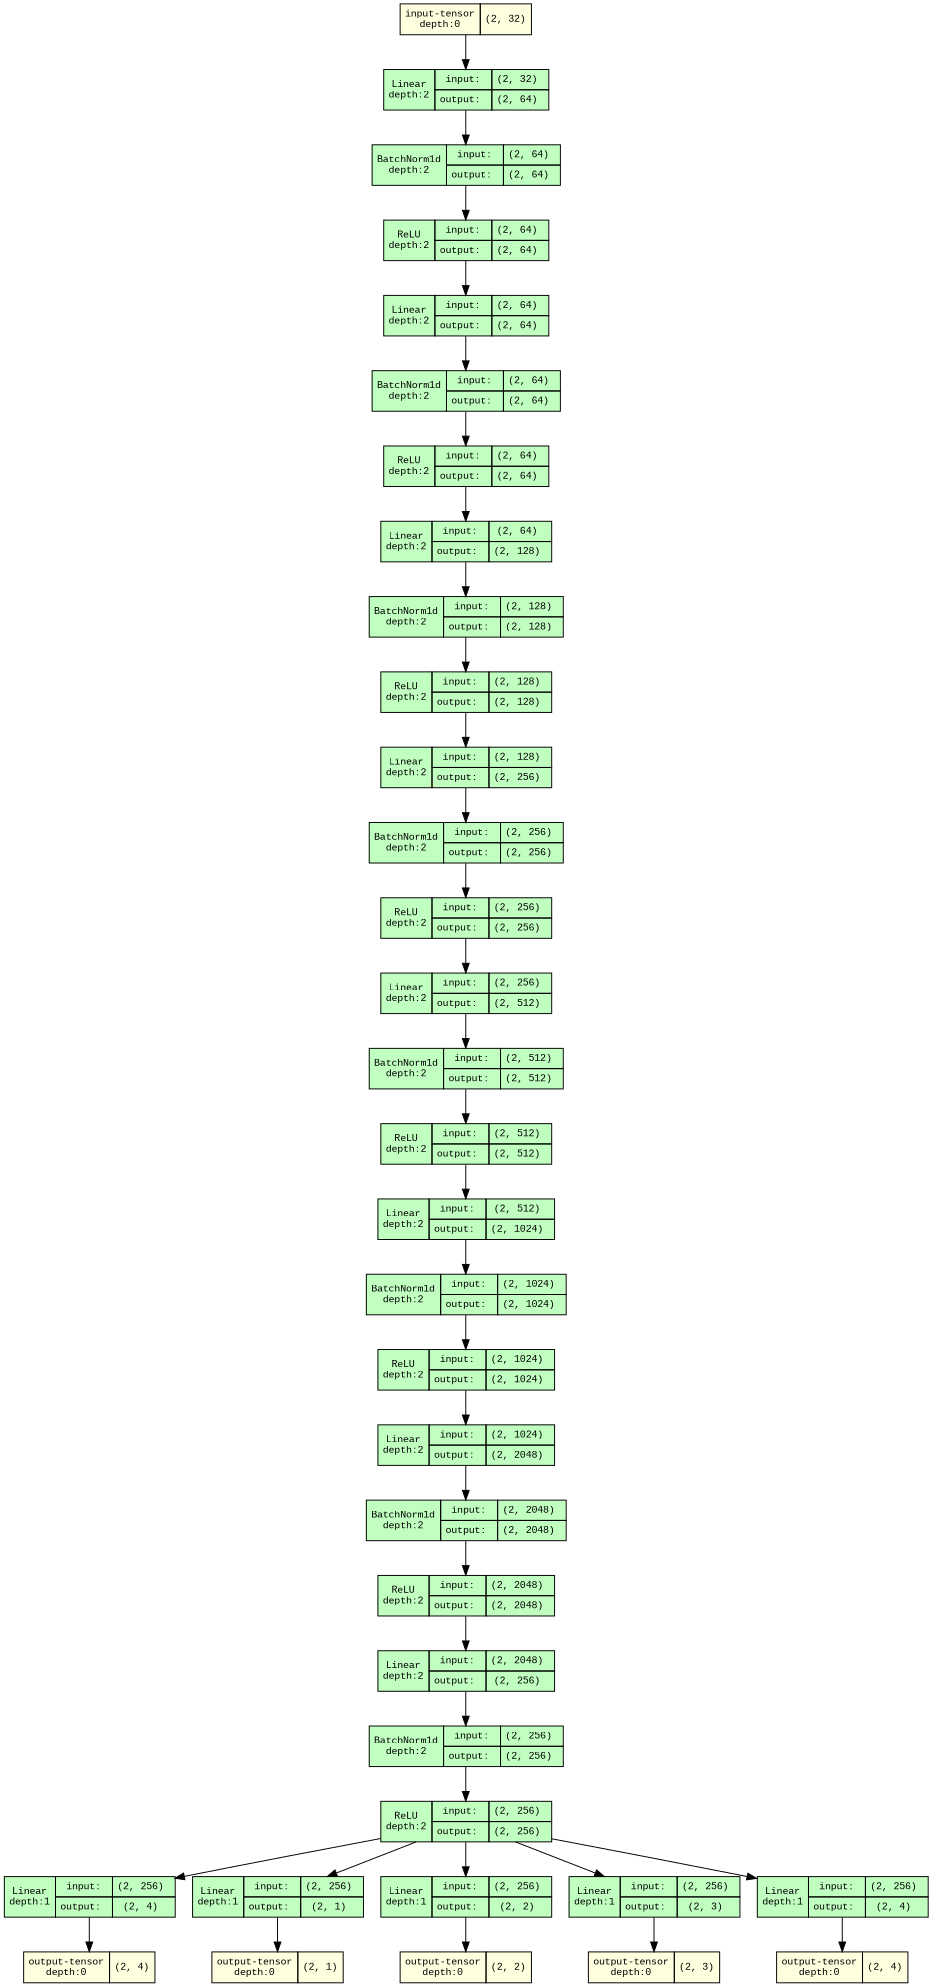

Initial loss -> Total: 204.2680 | Class: 1.4443 | Reg: 202.8237


In [25]:
import torch
from models.network import DOANet, export_model_png
from training.loss import DOALoss
from PIL import Image

# Detect if GPU is available and set the device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = DOANet(input_dim=2 * 16).to(device)
criterion = DOALoss()

print(f"Total parameters: {sum(p.numel() for p in model.parameters()):,}")

# 4. Export model architecture to PNG and display it
export_model_png(model, input_dim=2 * 16, filename="assets/doa_net")
display(Image.open("assets/doa_net.png"))

# 5. Quick forward pass test on one batch
x, k, doa, snr = next(iter(train_loader))

# Move batch data to the same device as the model
x = x.to(device)
k = k.to(device)
doa = doa.to(device)

class_logits, doa_preds = model(x)
loss, loss_class, loss_reg = criterion(class_logits, doa_preds, k, doa)
print(f"Initial loss -> Total: {loss.item():.4f} | Class: {loss_class.item():.4f} | Reg: {loss_reg.item():.4f}")

## Model training

In [27]:
import os
import torch
import matplotlib.pyplot as plt
from training.trainer import train_model

SKIP_TRAINING = True # <-- Set to True to skip training and load the saved model
WEIGHTS_PATH = "weights/doa_model.pt"

if SKIP_TRAINING:
    os.chdir("/content/doa-estimation-mlp")
    model.load_state_dict(torch.load(WEIGHTS_PATH, map_location=device))
    model.eval()
    print(f"Model loaded from {WEIGHTS_PATH} (training skipped)")
else:
    history = train_model(
        model=model,
        train_loader=train_loader,
        val_loader=val_loader,
        criterion=criterion,
        epochs=50,
        lr=1e-3,
    )

    # Automatic saving to weights/doa_model.pt
    os.makedirs("weights", exist_ok=True) 
    torch.save(model.state_dict(), WEIGHTS_PATH) 
    print(f" Model saved in {WEIGHTS_PATH}") 

    # Display of train/val curves 
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4)) 
    ax1.plot(history["train_loss"], label="Train Loss") 
    ax1.plot(history["val_loss"], label="Val Loss") 
    ax1.set_title("Loss over Epochs") 
    ax1.set_xlabel("Epoch") 
    ax1.set_ylabel("Loss") 
    ax1.legend() 
    ax1.grid(True) 

    ax2.plot(history["val_acc"], color="green", label="Val Accuracy (%)") 
    ax2.set_title("Source Count Accuracy (K)") 
    ax2.set_xlabel("Epoch") 
    ax2.set_ylabel("Accuracy (%)") 
    ax2.legend() 
    ax2.grid(True) 

    plt.tight_layout() 
    plt.show()

Model loaded from weights/doa_model.pt (training skipped)


## Model Evaluation by SNR

We evaluate the trained model on the unseen test set using the exact same logic as during training (sorting predicted angles per source count $K$ to match the ground truth). The only difference is that we group the results by **SNR level** to plot two metrics:
- **Source Count Accuracy (%):** Percentage of snapshots where the model predicts the exact number of signals $K \in \{1, 2, 3, 4\}$.
- **DOA RMSE (degrees):** Root Mean Squared Error of the predicted angles at each SNR.

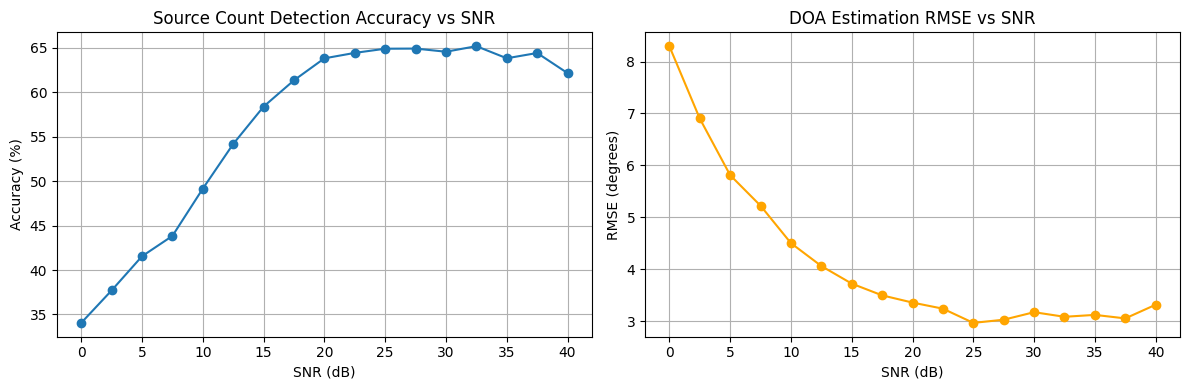

In [28]:
import os

os.chdir("/content/doa-estimation-mlp")

from evaluation.metrics import evaluate_by_snr, plot_snr_results

snrs, acc_per_snr, rmse_per_snr = evaluate_by_snr(model, test_loader)
plot_snr_results(snrs, acc_per_snr, rmse_per_snr)

## Results Analysis

### Training & Validation Curves
- **Loss over Epochs:** Both training and validation losses decrease smoothly and stabilize around epoch 20, showing good convergence without major overfitting.
- **Validation Accuracy:** Source count detection accuracy ($K \in \{1, 2, 3, 4\}$) steadily improves from ~43% to ~58% as the network learns to separate multi-source snapshots.

### Test Performance vs. SNR
- **Higher SNR improves both metrics:** As the signal becomes cleaner (from $0\text{ dB}$ to $40\text{ dB}$), source count accuracy rises from **35% to ~65%** while DOA estimation error drops from **8.2° down to ~3.0° RMSE**.
- **Takeaway & Limitations:** Even with a single snapshot ($T=1$) and an unknown number of sources, the MLP learns meaningful angular representations, though closely spaced sources at low SNR remain challenging to resolve.

## Conclusion



Overall, the training curves and SNR trends confirm that the multi-head MLP learns to jointly estimate the number of sources $K$ and their angles from a single snapshot ($T=1$). However, our final performance (~3.0° RMSE and ~65% source count accuracy at high SNR) remains far behind the accuracy reported in the reference paper.

## AI Usage Statement

**Approximate percentage of AI-assisted code:** 60%

**How AI was used:**
- Structuring the repository into modular `.py` files (`data/`, `models/`, `training/`, `evaluation/`) and providing boilerplate code for the PyTorch `Dataset`, `DataLoader`, multi-head MLP (`DOANet`), and training loop.
- Vectorizing the masked loss (`DOALoss`) and SNR-grouped evaluation (`evaluate_by_snr`) functions to avoid slow Python loops over batches.
- Setting up the development workflow across WSL, GitHub, and Google Colab (GPU runtime setup, model checkpointing with `torch.save`, and `SKIP_TRAINING` mode).
- Generating Matplotlib plotting utilities and refining Markdown explanations in the notebook.